In [2]:
import numpy as np
import matplotlib.pyplot as plt
import re

import ase.io as aio



In [3]:
def get_atom_numers(w_uc, n_replica, N_O_mag_uc, N_Fe_mag_uc, N_OS_uc, N_FeS_uc, N_FeS2_uc ):
    #calculate number of atom in the whole config, of every species and per surface.
    #determine the size factor "f"
    
    
    f=n_replica**2 #scaling factor
   
    
    #species
    N_water=int(w_uc*f*2)         #*2 surfaces
    N_H=int(N_water*2)             
    N_O_mag=N_O_mag_uc*f
    N_O=N_O_mag+N_water
    N_Fe=N_Fe_mag_uc*f
    N_atom=N_H+N_O+N_Fe

    #surface
    N_OS=N_OS_uc*f
    N_FeS=N_FeS_uc*f
    N_FeS2= N_FeS2_uc*f
    
    print(f"N_water = {N_water}")
    print(f"N_H = {N_H}")
    print(f"N_O = {N_O}")
    print(f"N_Fe = {N_Fe}")
    print(f"N_atom = {N_atom}")
    print(f"N_O surface = {N_OS}")
    print(f"N_Fe surface = {N_FeS}")
    print(f"N_Fe surface2 = {N_FeS2}")
    return( f, N_water, N_H, N_O, N_Fe, N_OS, N_FeS, N_FeS2 )

def get_diagonal_lenght( n_replica, L_x_uc, L_y_uc):
    L_x=L_x_uc*n_replica
    L_y=L_y_uc*n_replica
    diag_lenght=np.sqrt(L_x**2+L_y**2) #simulation box xy diagonal lenght to add boundaries 
    print("diag_lenght=" , diag_lenght)
    return(diag_lenght)
    

In [6]:
def parser_full_coverage(t_slice,  z_interval_u, z_interval_d,  N_water, N_OS, N_FeS, N_FeS2):
    
  
    O=[]
    OS_u=[]
    OS_d=[]
    FeS_u=[]
    FeS_d=[]
    FeS2_u=[]
    FeS2_d=[]
    
    
    positions=t_slice.get_positions(wrap=True)
    z=positions[:,2]
    #indices species 
    H_indices = np.where(t_slice.get_atomic_numbers()==1)[0]
    O_indices = np.where(t_slice.get_atomic_numbers()==2 )[0]
    Fe_indices = np.where(t_slice.get_atomic_numbers()==3 )[0]
    #indices regions 
    water_indices=np.where( (z > z_interval_u[0] ) |  (z < z_interval_d[0]) )[0]
    
    S_u_indices=np.where(  (z < z_interval_u[0] ) &  (z > z_interval_u[1]) )[0]
    S_d_indices=np.where(  (z < z_interval_d[1] ) &  (z > z_interval_d[0]) )[0]
    
    S2_u_indices=np.where( (z < z_interval_u[1] ) &  (z > z_interval_u[2]) )[0] 
    S2_d_indices=np.where( (z < z_interval_d[2] ) &  (z > z_interval_d[1]) )[0]
    
    
    #H
    H=positions[H_indices]
   
    #O 
    O= positions[list(set(O_indices).intersection(set(water_indices)))]     #water
    OS_u= positions[list(set(O_indices).intersection(set(S_u_indices)))]    #surface up
    OS_d= positions[list(set(O_indices).intersection(set(S_d_indices)))]    #surface down
    #Fe
    FeS_u= positions[list(set(Fe_indices).intersection(set(S_u_indices)))]    #surface up
    FeS_d= positions[list(set(Fe_indices).intersection(set(S_d_indices)))]    #surface down
    FeS2_u= positions[list(set(Fe_indices).intersection(set(S2_u_indices)))]    #2 surface up
    FeS2_d= positions[list(set(Fe_indices).intersection(set(S2_d_indices)))]    #2 surface down
    
    #checks
    if len(H) != N_water*2:
      print(f"H Err:  {len(H) - N_water*2} atom" )
    if len(O) != N_water:
      print(f"O Err: {len(O) - N_water} atom" ) 
    if len(OS_u) != N_OS:
      print(f"OS_u Err: {len(OS_u) - N_OS} atom" )
    if len(OS_d) != N_OS:
      print(f"OS_d Err: {len(OS_d) - N_OS} atom" )
    if len(FeS_u) != N_FeS:
      print(f"FeS_u Err: {len(FeS_u) - N_FeS} atom" )
    if len(FeS_d) != N_FeS:
      print(f"FeS_d Err: {len(FeS_d) - N_FeS} atom" )
    if len(FeS2_u) != N_FeS2:
      print(f"FeS2_u Err: {len(FeS2_u) - N_FeS2} atom" )
    if len(FeS2_d) != N_FeS2:
      print(f"FeS2_d Err: {len(FeS2_d) - N_FeS2} atom" )
     
    
   
    return H, O, OS_u, OS_d, FeS_u, FeS_d, FeS2_u, FeS2_d

In [11]:
#give #H or #O of water, z of the surface up and down , and cut distance
# 1)split atom above and beyond surfaces up to cut distance. 
# 2) (surface u) shifting z to zero, (surface d) shifting  z to zero  and inverting
def surface_up_down_split(A, z_u, z_d,  max_distance):
    
    tmp_u=[]
    tmp_d=[]
  
    for atom in A:
        if  z_u  <atom[2]<  z_u + max_distance  :
            tmp_u.append( [atom[0], atom[1],    atom[2]-z_u ])
        elif z_d -  max_distance < atom[2]<  z_d:
            tmp_d.append([atom[0], atom[1], -atom[2]+z_d])
  


    return tmp_u, tmp_d



#does:  (surface u) shifting z to zero, (surface d) shifting  z to zero  and inverting
def surface_up_down_translate(A_u, A_d, z_u, z_d,  max_distance):
    
    tmp_u=[]
    tmp_d=[]
  
    for atom in A_u:
        if  atom[2] <  z_u + max_distance  :
            tmp_u.append( [atom[0], atom[1],    atom[2]-z_u ])
            
    for atom in A_d:    
       if z_d -  max_distance < atom[2]:
            tmp_d.append([atom[0], atom[1], -atom[2]+z_d])
  


    return tmp_u, tmp_d

#extract z for u and d and put in the same list
def up_down_z_all_t_extractor(H_u, H_d ):
    zH_ud=[]
    for atom in H_u:
            zH_ud.append(atom[2])
    for atom in H_d:
            zH_ud.append(atom[2])

    return zH_ud
#takes: atoms in a layer
#determine exactly the surfaces positions with average of z of all atom in the surface: 
def get_layer_z(A):
    z=A[:,2]
    return np.mean(z), max(z), min(z)

In [12]:
#oct and tet analysis based on oxygens surface layer: OS_u or OS_d as input, box xy diagonal, and  cluster parm epsilon =1

#output diagonal O raws displacment to separate (Fe) oct and tet zones
def get_diagonal_O_raws(OS_u, control, diag_lenght,  epsilon):
    diagonal_projection=[]

    
    for atom in OS_u:
        r=np.sqrt(atom[0]**2+atom[1]**2)
        theta=np.arctan(atom[1]/atom[0])
        #print(theta)
        if control == 'u':
            diagonal_projection.append(r*np.cos(theta - (np.pi/4)  )   )
        elif control == 'd':
            diagonal_projection.append(r*np.sin(theta - (np.pi/4)  )   )
        else:
            print("control must be 'u' or 'd'")
            return

    #clusterization of diagonal projection of O position in raws
    displacement=[]
    
    displacement.append([diagonal_projection[0]])

    for i, proj in enumerate(diagonal_projection[1:]):
        copy=displacement
     
        for j in range(len(copy)):
            #print(j)
            if np.abs(proj-displacement[j][0])<epsilon:
                displacement[j].append(proj)
                #print("existing")
                break
            elif j==len(copy)-1:      #last round and no match found create new entry
                #print("new")
                displacement.append([proj])


    #average over the O diagonal raws
    diag_raws=[]   
    for i in displacement:
        diag_raws.append(np.mean(i))
        
    diag_raws=list(np.sort(diag_raws))
   
    if control == 'u':
        diag_raws.insert(0,0)
        diag_raws.append(diag_lenght)
    else:
        diag_raws.insert(0,-diag_lenght/2)
        diag_raws.append(diag_lenght/2)
    #print(diag_raws)
    return diag_raws


#oct/tet regions atomic separation; inside O raws = oct, outside = tet: 
def tet_oct_split(O_u, diag_raw , control ):
      
    O_oct_u=[]
    O_tet_u=[]
   
    for atom in O_u:
        r=np.sqrt(atom[0]**2+atom[1]**2)
        theta=np.arctan(atom[1]/atom[0])
    
        if control == 'u':
            diagonal_projection=(r*np.cos(theta - (np.pi/4)  ))     #up cos raws   \\\\\           
        elif control == 'd':
            diagonal_projection=(r*np.sin(theta - (np.pi/4)  ))     #down sin raws  /////   
            
        else:  
            print("control must be 'u' or 'd'")
            return   
        
        if diagonal_projection <diag_raw[0] or diagonal_projection > diag_raw[-1]:  #inbound check
                print("OUT of bounds: diag =" , diagonal_projection, "cartesian =", atom)
                
        if (diag_raw[2]-diag_raw[1])<(diag_raw[3]-diag_raw[2]):           #check if the first raw (the zero is the border)is oct or tet (if T == oct if F ==tet )
            # first raw is oct
            #if diagonal projection in (diag_raw[2n],diag_raw[2n+1])   then tet region  even!
            #if diagonal projection in (diag_raw[2n+1],diag_raw[2n+2]) then oct region odd!
            for n in range(len(diag_raw)-1):  
                if diag_raw[n] <= diagonal_projection <= diag_raw[n+1]: 
                    if n % 2 ==0:
                        O_tet_u.append([atom[0], atom[1], atom[2]]) #n even ==> outside O raws == tet region
                    else:
                        O_oct_u.append([atom[0], atom[1], atom[2]]) #n odd ==> inside O raws == oct region
                    break
        else:
            #first raw is tet
            for n in range(len(diag_raw)-1):  
                if diag_raw[n] <= diagonal_projection <= diag_raw[n+1]: 
                    if n % 2 ==0:
                        O_oct_u.append([atom[0], atom[1], atom[2]]) #n even ==> inside O raws == oct region
                    else:
                        O_tet_u.append([atom[0], atom[1], atom[2]]) #n odd ==> outside O raws == tet region
                    break
        
    if len(O_oct_u)+len(O_tet_u) != len(O_u):
        print("MISSING TET/OCT ATOM: ",len(O_u)-  (len(O_oct_u)+len(O_tet_u))) 
    return O_oct_u,  O_tet_u

In [30]:
# FIRST PAPER
# magnetite 1 u.c. data
#8.396 0.0 0.0
#0.0 8.396 0.0
#0.0 0.0 34.7337
#O Fe
#72 50

#number of O/Fe atom per uc
N_O_mag_uc=64               #second paper  N_O_mag_uc=64    
N_Fe_mag_uc=44              #second paper  N_Fe_mag_uc=44
#box lenght unit cell!
L_x_uc=8.396                #second paper same (8.396)
L_y_uc=8.396

#SCV structure (1uc)
N_OS_uc=8    # number oxygen in first outer layer/uc
N_FeS_uc=4   # number of iron in first outer layer/uc
N_FeS2_uc=3  # number of iron  second/outer layer/uc



#IMPORTANT: trj must be ordered by z and clustered by atom
trj="./full_coverage/run_4/trjmagnetite.dump"      #path to trj
#water per u.c. per surface
w_uc=68                                #second paper full= 68
n_replica=4                              #if it is replicated 2x2 n_replica=2        

#bouyndaries
z_interval_u=[42.5, 41.1, 40.1]     
z_interval_d=[26.29, 27.45, 28.3]   




#size factor, tot number of H, O, Fe, number of O in the magnetite surface and Fe in the 2 outermost layers 
f, N_water, N_H, N_O, N_Fe, N_OS, N_FeS, N_FeS2 =get_atom_numers(w_uc, n_replica, N_O_mag_uc, N_Fe_mag_uc, N_OS_uc, N_FeS_uc, N_FeS2_uc )

diag_lenght= get_diagonal_lenght( n_replica, L_x_uc, L_y_uc)

N_water = 2176
N_H = 4352
N_O = 3200
N_Fe = 704
N_atom = 8256
N_O surface = 128
N_Fe surface = 64
N_Fe surface2 = 48
diag_lenght= 47.49494827873803


In [31]:

#PROFILE DENSITY LOOP

control_u='u'
control_d='d'    #second paper control_d='d'   , here is not needed because the 2 surfaces have the same orientation oct/tet 

max_distance=25    #max cut distance from each surface: <26 

#hinstograms init
n_bin=500
dx=1/(n_bin-1)*max_distance
bins = np.linspace(0, max_distance, n_bin) 
bins_centers=(bins[1:]+bins[:-1])/2


H_ud_hist=[0]*(n_bin-1)
O_ud_hist=[0]*(n_bin-1)
N_H_ud=0       #Total Number of H up and down in every t
N_O_ud=0
H_tet_ud_hist=[0]*(n_bin-1)
H_oct_ud_hist=[0]*(n_bin-1)
O_tet_ud_hist=[0]*(n_bin-1)
O_oct_ud_hist=[0]*(n_bin-1)
N_H_oct_ud=0
N_H_tet_ud=0
N_O_oct_ud=0
N_O_tet_ud=0
#time
t=0
for t_slice in aio.iread(trj,format='lammps-dump-text'):
     
     #parsing
     H, O,  OS_u, OS_d, FeS_u, FeS_d, FeS2_u, FeS2_d = parser_full_coverage(t_slice,  z_interval_u, z_interval_d,  N_water, N_OS, N_FeS, N_FeS2)
     
     if t %10 == 0:   #it does every 10 steps
          #get layer update infos of surfaces and second layer
          #first 
          S_u, S_u_min, S_u_max =get_layer_z(np.concatenate((OS_u,FeS_u),axis=0 ))
          S_d, S_d_min, S_d_max =get_layer_z(np.concatenate((OS_d,FeS_d),axis=0 ))     
          #second
          S2_d, S2_d_min, S2_d_max =get_layer_z(FeS2_d)
          S2_u, S2_u_min, S2_u_max =get_layer_z(FeS2_u)
          
          #only for the parser of the full coverage: update surfaces z intervals to determine the atoms (not really working the atoms are moving too much)
          #z_interval_u=[S_u_max+eps,  (S_u_min+ S2_u_max)/2, S2_u_min-eps  ]
          #z_interval_d=[S_d_min-eps,  (S_d_max+ S2_d_min)/2, S2_d_max+eps  ] 

          #get O raws info
          diag_raw_u=get_diagonal_O_raws(OS_u, control_u, diag_lenght, 1 ) #give OS_u or OS_d, control u or d accordingly, diag_lenght and cluster param
          diag_raw_d=get_diagonal_O_raws(OS_d, control_d, diag_lenght, 1 ) #give OS_u or OS_d, control u or d accordingly, diag_lenght and cluster param
     
      
     # translate to 0 the surfaces (and invert the d)
     H_u, H_d=surface_up_down_split(H, S_u, S_d,  max_distance)
     O_u, O_d=surface_up_down_split(O, S_u, S_d,  max_distance)
     
     #UP DOWN DENSITY PLOT
     #extract z and unify
     zH_ud=up_down_z_all_t_extractor(H_u, H_d )                 
     zO_ud=up_down_z_all_t_extractor(O_u, O_d )
     
     #make instograms NOT normalized, NOT density
     H_ud_hist+=np.histogram(zH_ud, bins=bins)[0]
     N_H_ud+=len(zH_ud)    
     O_ud_hist+=np.histogram(zO_ud, bins=bins)[0]
     N_O_ud+=len(zO_ud)
     
     #OCT/TET UP/DOWN DENSITY PLOT
     #split oct/tet
     O_oct_u, O_tet_u=tet_oct_split(O_u, diag_raw_u , control_u )     
     O_oct_d, O_tet_d=tet_oct_split(O_d, diag_raw_d , control_d )
     H_oct_u, H_tet_u=tet_oct_split(H_u, diag_raw_u , control_u )
     H_oct_d, H_tet_d=tet_oct_split(H_d, diag_raw_d , control_d )
     #extract z and unify
     zH_tet_ud= up_down_z_all_t_extractor(H_tet_u, H_tet_d)           
     zH_oct_ud= up_down_z_all_t_extractor(H_oct_u, H_oct_d)
     zO_tet_ud= up_down_z_all_t_extractor(O_tet_u, O_tet_d)
     zO_oct_ud= up_down_z_all_t_extractor(O_oct_u, O_oct_d)
     
     #make instograms NOT normalized, NOT density
     H_tet_ud_hist+=np.histogram(zH_tet_ud, bins=bins)[0]
     N_H_tet_ud+=len(zH_tet_ud)

     H_oct_ud_hist+=np.histogram(zH_oct_ud, bins=bins)[0]
     N_H_oct_ud+=len(zH_oct_ud)

     O_tet_ud_hist+=np.histogram(zO_tet_ud, bins=bins)[0]
     N_O_tet_ud+=len(zO_tet_ud) 

     O_oct_ud_hist+=np.histogram(zO_oct_ud, bins=bins)[0]
     N_O_oct_ud+=len(zO_oct_ud)   
     
     #updates counts
     #print(t)
     t+=1
     

FeS_d Err: 1 atom
FeS2_d Err: -1 atom
FeS_d Err: 1 atom
FeS2_d Err: -1 atom
FeS_d Err: 1 atom
FeS2_d Err: -1 atom
FeS_u Err: 1 atom
FeS2_u Err: -1 atom
FeS_d Err: -1 atom
FeS_u Err: 1 atom
FeS2_u Err: -1 atom
FeS2_d Err: -1 atom
FeS_d Err: 1 atom
FeS2_d Err: -1 atom
FeS2_d Err: -1 atom
FeS_d Err: 1 atom
FeS2_d Err: -1 atom
FeS_d Err: -1 atom
FeS_u Err: 1 atom
FeS2_u Err: -1 atom
FeS_d Err: -1 atom


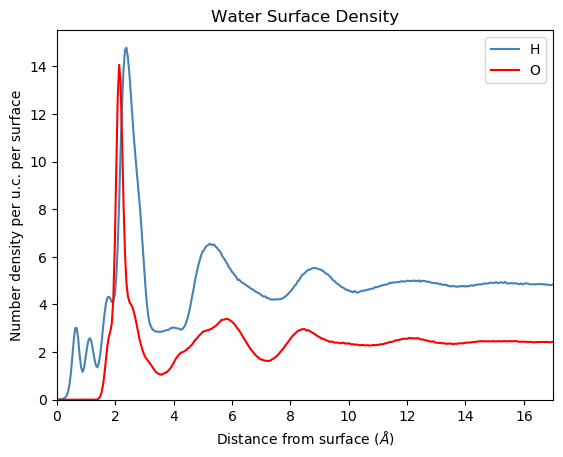

In [128]:


plt.plot(bins_centers,H_ud_hist/(t*dx*2*f), label='H', color='steelblue')    #/(N_H_ud*t*dx) for normalization
plt.plot(bins_centers,O_ud_hist/(t*dx*2*f),label='O', color='r')
plt.legend()
plt.xlabel('Distance from surface ($\\AA$)')
plt.ylabel('Number density per u.c. per surface')
plt.title(f"Water Surface Density")
plt.xlim(0,20)
plt.ylim(0)
#plt.savefig(f"W_density_profile_{w_uc}w_uc.png", bbox_inches="tight", facecolor="white", transparent=True, dpi=700)

plt.show()

In [131]:
#peak integration


H_hist_uc_surface=H_ud_hist/(t*dx*2*f)

mask_H_first_peak=np.where(bins_centers<0.93)[0]
mask_H_second_peak=np.where( (0.9 < bins_centers ) & ( bins_centers < 1.4) )[0]
mask_H_third_peak=np.where( (1.4 < bins_centers ) & ( bins_centers < 1.9) )[0]

print("H first peak = " , np.trapz(H_hist_uc_surface[mask_H_first_peak]  ,bins_centers[mask_H_first_peak] ))
print("H second peak = " ,np.trapz(H_hist_uc_surface[mask_H_second_peak]  ,bins_centers[mask_H_second_peak] ))
print("H third peak = " ,np.trapz(H_hist_uc_surface[mask_H_third_peak]    ,bins_centers[mask_H_third_peak] ))


O_hist_uc_surface=O_ud_hist/(t*dx*2*f)

mask_O_first_peak=np.where(bins_centers<3.5)[0]
mask_O_second_peak=np.where( (3.5 < bins_centers ) & ( bins_centers < 7.5) )[0]


print("O first peak = " , np.trapz(H_hist_uc_surface[mask_O_first_peak]  ,bins_centers[mask_O_first_peak] ))
print("O second peak = " ,np.trapz(H_hist_uc_surface[mask_O_second_peak]  ,bins_centers[mask_O_second_peak] ))

H first pick =  1.0218702554624068
H second pick =  0.9082922140075256
H third pick =  1.5357232738134534
O first pick =  15.983286850617207
O second pick =  18.488785357119284


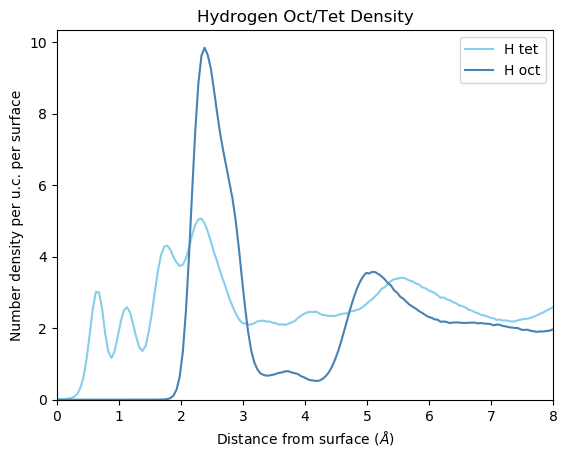

In [79]:

plt.plot(bins_centers,H_tet_ud_hist/(t*dx*2*f), label='H tet',  color='skyblue')  #/(N_O_oct_ud*t*dx) for normalization
#plt.plot(bins_centers,O_tet_ud_hist/(t*dx*2*f),label='O tet',   color='steelblue')
plt.plot(bins_centers,H_oct_ud_hist/(t*dx*2*f), label='H oct',  color='steelblue')  #/(N_O_oct_ud*t*dx) for normalization
#plt.plot(bins_centers,O_oct_ud_hist/(t*dx*2*f),label='O oct',   color='g')
plt.legend()
plt.xlabel('Distance from surface ($\\AA$)')
plt.ylabel('Number density per u.c. per surface')
plt.title(f"Hydrogen Oct/Tet Density")
plt.xlim(0,8)
plt.ylim(0)
#plt.savefig(f"H_oct_tet_density_profile_{w_uc}w_uc.png", bbox_inches="tight", facecolor="white", transparent=True, dpi=700)
plt.show()

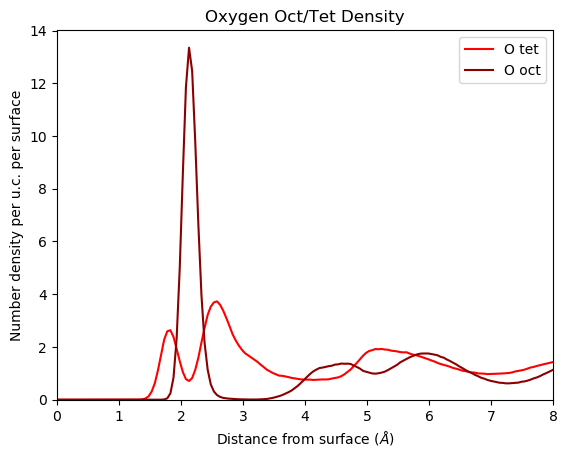

In [129]:
#plt.plot(bins_centers,H_tet_ud_hist/(t*dx*2*f), label='H tet',  color='skyblue')  #/(N_O_oct_ud*t*dx) for normalization
plt.plot(bins_centers,O_tet_ud_hist/(t*dx*2*f),label='O tet',   color='r')
#plt.plot(bins_centers,H_oct_ud_hist/(t*dx*2*f), label='H oct',  color='steelblue')  #/(N_O_oct_ud*t*dx) for normalization
plt.plot(bins_centers,O_oct_ud_hist/(t*dx*2*f),label='O oct',   color='darkred')
plt.legend()
plt.xlabel('Distance from surface ($\\AA$)')
plt.ylabel('Number density per u.c. per surface')
plt.title(f"Oxygen Oct/Tet Density")
plt.xlim(0,8)
plt.ylim(0)
#plt.savefig(f"O_oct_tet_density_profile_{w_uc}w_uc.png", bbox_inches="tight", facecolor="white", transparent=True, dpi=700)
plt.show()